<a href="https://www.kaggle.com/code/iceiksky/lb11-3-10?scriptVersionId=369884008" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

## 1. Імпорт бібліотек і налаштування

In [8]:
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

IMG_SIZE = 32
NUM_CLASSES = 43
BATCH_SIZE = 128  # Більший пакет = менше кроків на епоху
MAX_PER_CLASS = 500  # Максимум зображень кожного класу для навчання
EPOCHS = 8

print('TensorFlow:', tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPU:', gpus if gpus else 'Немає GPU! Рекомендується увімкнути GPU в налаштуваннях.')

TensorFlow: 2.21.0
GPU: Немає GPU! Рекомендується увімкнути GPU в налаштуваннях.


## 2. Підключення датасету GTSRB

In [9]:
# На Kaggle шукаємо вже доданий датасет у /kaggle/input.
# У Google Colab завантажуємо його через kagglehub.
root = None
kaggle_input = Path('/kaggle/input')
if kaggle_input.exists():
    for candidate in kaggle_input.rglob('Train.csv'):
        if (candidate.parent / 'Test.csv').exists():
            root = candidate.parent
            break

if root is None:
    try:
        import kagglehub
    except ImportError:
        %pip -q install kagglehub
        import kagglehub
    try:
        dataset_dir = Path(kagglehub.dataset_download(
            'meowmeowmeowmeowmeow/gtsrb-german-traffic-sign'
        ))
        roots = [f.parent for f in dataset_dir.rglob('Train.csv')
                 if (f.parent / 'Test.csv').exists()]
        if not roots:
            raise FileNotFoundError('Не знайдено Train.csv та Test.csv')
        root = roots[0]
    except Exception as exc:
        raise RuntimeError('Не вдалося знайти GTSRB. У Kaggle додайте датасет через Add Input.') from exc

train_df = pd.read_csv(root / 'Train.csv')
test_df = pd.read_csv(root / 'Test.csv')
assert {'Path', 'ClassId'} <= set(train_df.columns)
assert {'Path', 'ClassId'} <= set(test_df.columns)

print('Шлях:', root)
print('Всього тренувальних зображень:', len(train_df))
print('Тестових зображень:', len(test_df))
print('Класів:', train_df.ClassId.nunique())
display(train_df[['Path', 'ClassId']].head())

Шлях: /kaggle/input/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign
Всього тренувальних зображень: 39209
Тестових зображень: 12630
Класів: 43


,Path,ClassId
0,Train/20/00020_00000_00000.png,20
1,Train/20/00020_00000_00001.png,20
2,Train/20/00020_00000_00002.png,20
3,Train/20/00020_00000_00003.png,20
4,Train/20/00020_00000_00004.png,20


## 3. Приклади дорожніх знаків

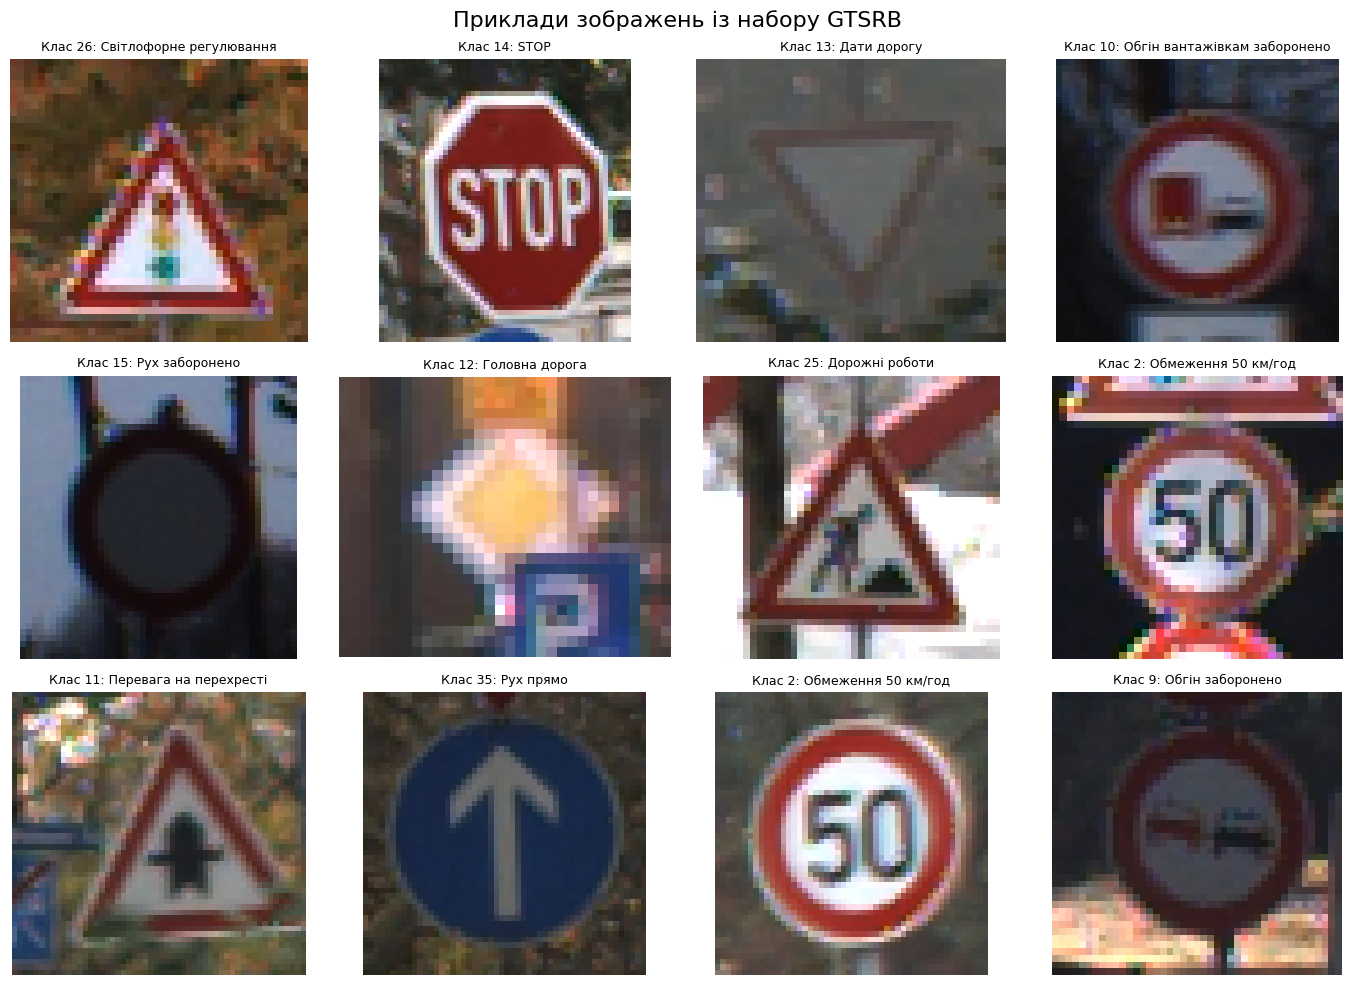

In [10]:
# Назви класів відповідно до порядку ClassId (0–42).
class_names = [
    'Обмеження 20 км/год', 'Обмеження 30 км/год',
    'Обмеження 50 км/год', 'Обмеження 60 км/год',
    'Обмеження 70 км/год', 'Обмеження 80 км/год',
    'Кінець обмеження 80 км/год', 'Обмеження 100 км/год',
    'Обмеження 120 км/год', 'Обгін заборонено',
    'Обгін вантажівкам заборонено', 'Перевага на перехресті',
    'Головна дорога', 'Дати дорогу', 'STOP',
    'Рух заборонено', 'Рух вантажівок заборонено',
    'В’їзд заборонено', 'Інші небезпеки',
    'Небезпечний поворот ліворуч', 'Небезпечний поворот праворуч',
    'Подвійний поворот', 'Нерівна дорога', 'Слизька дорога',
    'Звуження дороги праворуч', 'Дорожні роботи',
    'Світлофорне регулювання', 'Пішоходи', 'Діти',
    'Велосипедисти', 'Ожеледиця або сніг',
    'Дикі тварини', 'Кінець усіх обмежень',
    'Поворот праворуч', 'Поворот ліворуч',
    'Рух прямо', 'Прямо або праворуч', 'Прямо або ліворуч',
    'Об’їзд праворуч', 'Об’їзд ліворуч',
    'Круговий рух', 'Кінець заборони обгону',
    'Кінець заборони обгону вантажівкам'
]
assert len(class_names) == NUM_CLASSES

# CSV містить відносні шляхи до файлів зображень.
def image_path(relative_path):
    return root / str(relative_path).replace('\\', '/')

samples = train_df.sample(n=12, random_state=SEED)
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, (_, item) in zip(axes.flat, samples.iterrows()):
    with Image.open(image_path(item['Path'])) as img:
        ax.imshow(img.convert('RGB'))
    label = int(item['ClassId'])
    ax.set_title(f'Клас {label}: {class_names[label]}', fontsize=9)
    ax.axis('off')
plt.suptitle('Приклади зображень із набору GTSRB', fontsize=16)
plt.tight_layout()
plt.show()

## 4. Швидка підготовка даних

Для прискорення обмежуємо кількість тренувальних прикладів **до 500 на клас**, зберігаючи всі 43 класи. Тестові зображення **не** скорочуємо, щоб оцінка була чесною. Усі зображення приводимо до 32 × 32 RGB.

In [11]:
# Збалансовуємо за верхньою межею: кожен клас представлено, але великі класи зменшено.
fast_train_df = pd.concat(
    [group.sample(n=min(len(group), MAX_PER_CLASS), random_state=SEED)
     for _, group in train_df.groupby('ClassId')],
    ignore_index=True
).sample(frac=1, random_state=SEED).reset_index(drop=True)

print(f'Для швидкого навчання використовується {len(fast_train_df)} з {len(train_df)} зображень.')

# Відносні шляхи беруться з CSV датасету.
def image_path(relative_path):
    return root / str(relative_path).replace('\\', '/')

def load_images(frame, description):
    images = np.empty((len(frame), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    labels = frame['ClassId'].to_numpy(dtype=np.int32)
    for i, rel in enumerate(tqdm(frame['Path'], total=len(frame), desc=description)):
        with Image.open(image_path(rel)) as img:
            images[i] = np.asarray(img.convert('RGB').resize(
                (IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR
            ), dtype=np.uint8)
    return images, labels

X_all, y_all = load_images(fast_train_df, 'Навчальні зображення')
X_test, y_test = load_images(test_df, 'Тестові зображення')
X_train, X_val, y_train, y_val = train_test_split(
    X_all, y_all, test_size=0.15, random_state=SEED, stratify=y_all
)
del X_all, y_all

print('Навчальна вибірка:', X_train.shape)
print('Валідаційна вибірка:', X_val.shape)
print('Тестова вибірка:', X_test.shape)

train_ds = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
            .shuffle(min(len(X_train), 5000), seed=SEED)
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
val_ds = (tf.data.Dataset.from_tensor_slices((X_val, y_val))
          .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
test_ds = (tf.data.Dataset.from_tensor_slices((X_test, y_test))
           .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

Для швидкого навчання використовується 17970 з 39209 зображень.


Навчальні зображення:   0%|          | 0/17970 [00:00<?, ?it/s]

Тестові зображення:   0%|          | 0/12630 [00:00<?, ?it/s]

Навчальна вибірка: (15274, 32, 32, 3)
Валідаційна вибірка: (2696, 32, 32, 3)
Тестова вибірка: (12630, 32, 32, 3)


## 5. Архітектура компактної CNN

Три шари згортки `Conv2D`, три шари `MaxPooling2D`, повнозв’язний шар і `softmax` для 43 класів. Архітектура помітно легша за попередню.

In [12]:
tf.keras.backend.clear_session()
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    tf.keras.layers.Rescaling(1 / 255.0),
    tf.keras.layers.Conv2D(24, (3, 3), padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(48, (3, 3), padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(96, activation='relu'),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')
])
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 24)     │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 24)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 48)     │        10,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 48)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 64)       │        27,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 96)             │        98,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │         4,171 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 141,371 (552.23 KB)

 Trainable params: 141,371 (552.23 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Швидке навчання моделі

In [13]:
callbacks = [tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy', mode='max', patience=2, restore_best_weights=True
)]

start_time = time.perf_counter()
history = model.fit(train_ds, validation_data=val_ds,
                    epochs=EPOCHS, callbacks=callbacks, verbose=1)
print(f'Час навчання: {(time.perf_counter() - start_time) / 60:.1f} хв')

Epoch 1/8
120/120 ━━━━━━━━━━━━━━━━━━━━ 13s 92ms/step - accuracy: 0.1357 - loss: 3.2166 - val_accuracy: 0.3490 - val_loss: 2.3013
Epoch 2/8
120/120 ━━━━━━━━━━━━━━━━━━━━ 11s 91ms/step - accuracy: 0.4315 - loss: 1.8830 - val_accuracy: 0.6999 - val_loss: 1.0780
Epoch 3/8
120/120 ━━━━━━━━━━━━━━━━━━━━ 11s 92ms/step - accuracy: 0.6713 - loss: 1.0543 - val_accuracy: 0.8394 - val_loss: 0.6239
Epoch 4/8
120/120 ━━━━━━━━━━━━━━━━━━━━ 11s 93ms/step - accuracy: 0.7928 - loss: 0.6556 - val_accuracy: 0.8973 - val_loss: 0.4061
Epoch 5/8
120/120 ━━━━━━━━━━━━━━━━━━━━ 11s 92ms/step - accuracy: 0.8590 - loss: 0.4522 - val_accuracy: 0.9258 - val_loss: 0.2744
Epoch 6/8
120/120 ━━━━━━━━━━━━━━━━━━━━ 20s 91ms/step - accuracy: 0.9018 - loss: 0.3217 - val_accuracy: 0.9388 - val_loss: 0.2059
Epoch 7/8
120/120 ━━━━━━━━━━━━━━━━━━━━ 11s 91ms/step - accuracy: 0.9221 - loss: 0.2536 - val_accuracy: 0.9547 - val_loss: 0.1849
Epoch 8/8
120/120 ━━━━━━━━━━━━━━━━━━━━ 11s 91ms/step - accuracy: 0.9374 - loss: 0.2091 - val_accu

## 7. Криві навчання (Accuracy та Loss)

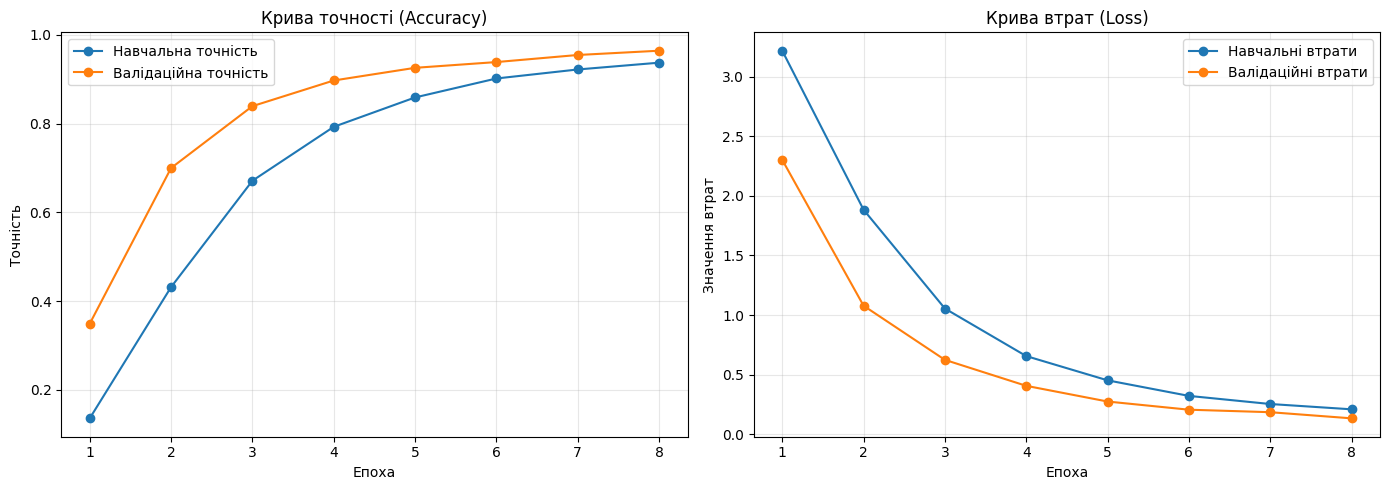

In [14]:
epochs = range(1, len(history.history['loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, history.history['accuracy'], label='Навчальна точність', marker='o')
axes[0].plot(epochs, history.history['val_accuracy'], label='Валідаційна точність', marker='o')
axes[0].set_title('Крива точності (Accuracy)')
axes[0].set_xlabel('Епоха')
axes[0].set_ylabel('Точність')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history.history['loss'], label='Навчальні втрати', marker='o')
axes[1].plot(epochs, history.history['val_loss'], label='Валідаційні втрати', marker='o')
axes[1].set_title('Крива втрат (Loss)')
axes[1].set_xlabel('Епоха')
axes[1].set_ylabel('Значення втрат')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('gtsrb_training_curves.png', dpi=180, bbox_inches='tight')
plt.show()

## 8. Перевірка точності на повному тестовому наборі

In [15]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f'Тестова точність (Accuracy): {test_accuracy * 100:.2f}%')
print(f'Тестові втрати (Loss): {test_loss:.4f}')

# Зберігаємо навчену модель.
model.save('gtsrb_cnn.keras')
print('Модель збережено у gtsrb_cnn.keras')

99/99 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.8808 - loss: 0.4766
Тестова точність (Accuracy): 88.08%
Тестові втрати (Loss): 0.4766
Модель збережено у gtsrb_cnn.keras


## 9. Візуалізація класифікації

Зелений заголовок — правильний прогноз, червоний — помилковий. Показуємо зображення, справжній і прогнозований клас.

99/99 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step


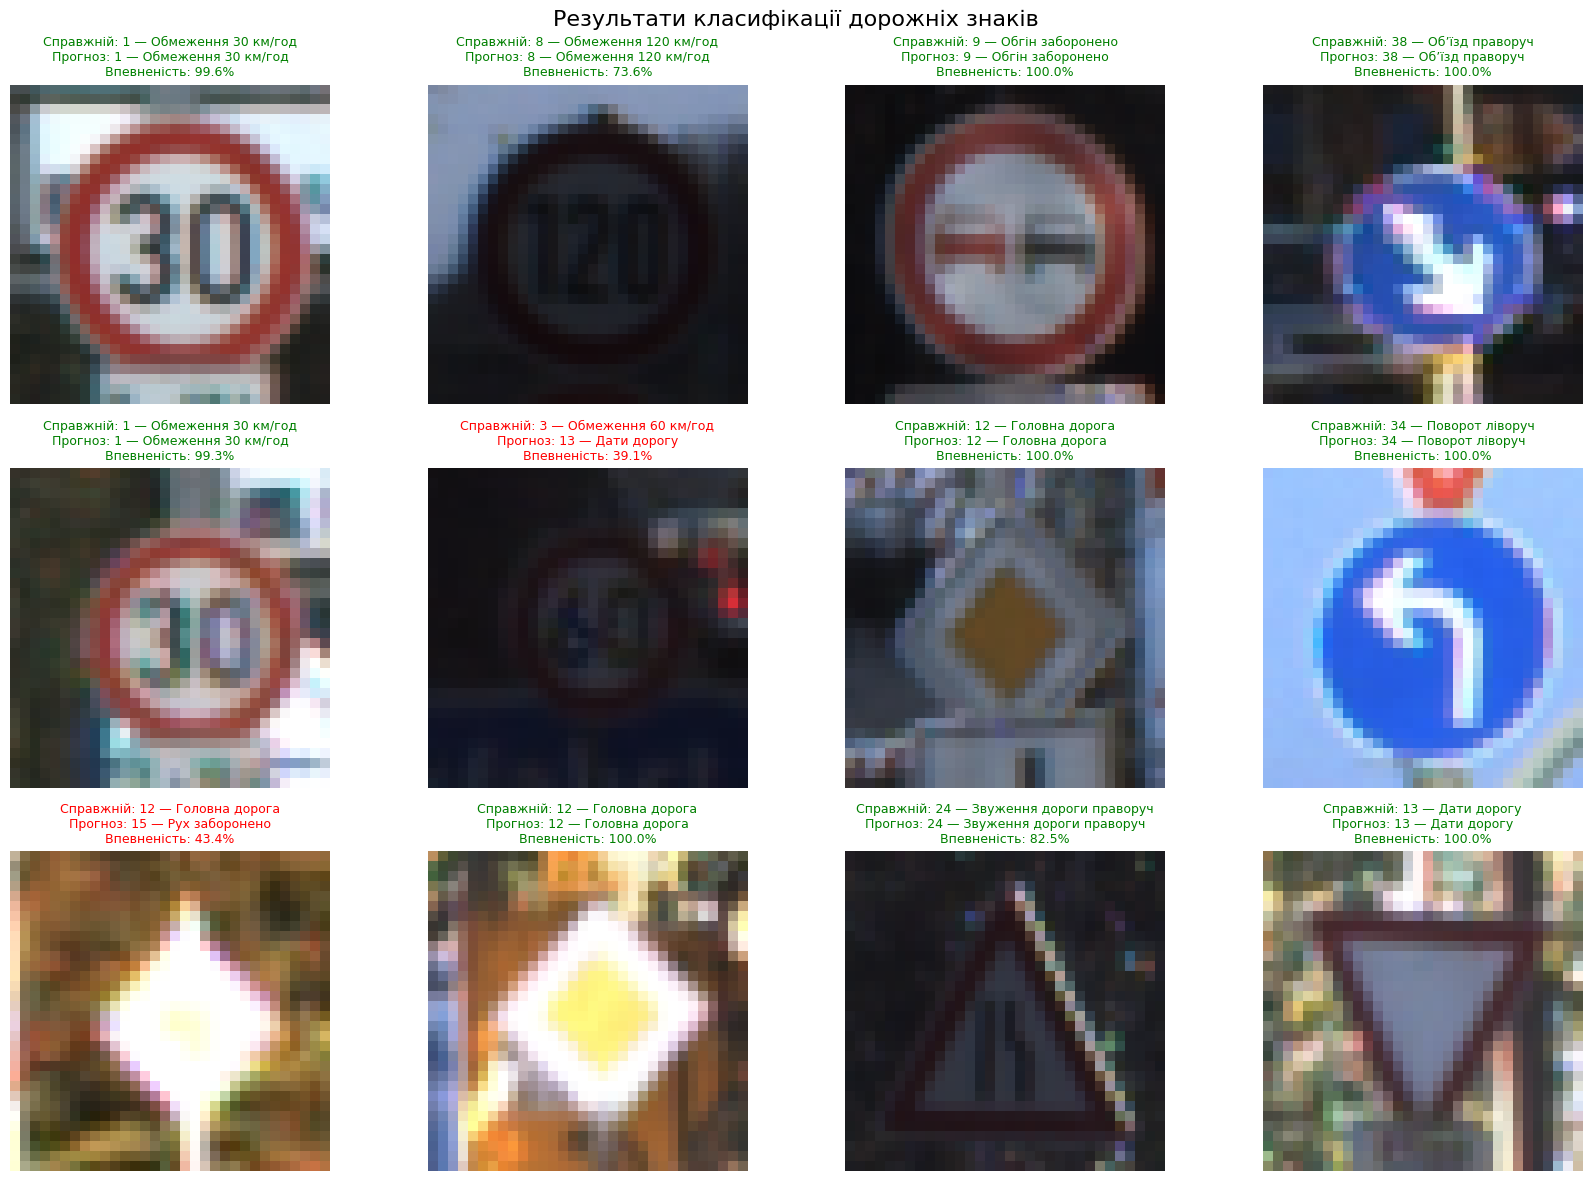

Правильно класифіковано: 11125 із 12630
Помилково класифіковано: 1505


In [16]:
probabilities = model.predict(test_ds, verbose=1)
predicted = np.argmax(probabilities, axis=1)

rng = np.random.default_rng(SEED)
indices = rng.choice(len(X_test), size=12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(17, 12))
for ax, idx in zip(axes.flat, indices):
    true_id = int(y_test[idx])
    pred_id = int(predicted[idx])
    confidence = float(probabilities[idx, pred_id]) * 100

    ax.imshow(X_test[idx])
    ax.set_title(
        f'Справжній: {true_id} — {class_names[true_id]}\n'
        f'Прогноз: {pred_id} — {class_names[pred_id]}\n'
        f'Впевненість: {confidence:.1f}%',
        fontsize=9,
        color='green' if true_id == pred_id else 'red'
    )
    ax.axis('off')

plt.suptitle('Результати класифікації дорожніх знаків', fontsize=16)
plt.tight_layout()
plt.savefig('gtsrb_predictions.png', dpi=180, bbox_inches='tight')
plt.show()

correct = int(np.sum(predicted == y_test))
print(f'Правильно класифіковано: {correct} із {len(y_test)}')
print(f'Помилково класифіковано: {len(y_test) - correct}')